# Problem Statement

Businesses or companies can fall prey to default if they are not able to keep up their debt obligations. Defaults will lead to a lower credit rating for the company which in turn reduces its chances of getting credit in the future and may have to pay higher interests on existing debts as well as any new obligations. From an investor's point of view, he would want to invest in a company if it is capable of handling its financial obligations, can grow quickly, and is able to manage the growth scale.

A balance sheet is a financial statement of a company that provides a snapshot of what a company owns, owes, and the amount invested by the shareholders. Thus, it is an important tool that helps evaluate the performance of a business.

Data that is available includes information from the financial statement of the companies for the previous year (2015). Also, information about the Networth of the company in the following year (2016) is provided which can be used to drive the labeled field.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.metrics as metrics

# Data Loading

In [2]:
Company = pd.read_excel('Company_Data2015-2.xlsx','Sheet2')
Company.head()

,Co_Code,Co_Name,Networth Next Year,Equity Paid Up,Networth,Capital Employed,Total Debt,Gross Block,Net Working Capital,Current Assets,...,PBIDTM (%)[Latest],PBITM (%)[Latest],PBDTM (%)[Latest],CPM (%)[Latest],APATM (%)[Latest],Debtors Velocity (Days),Creditors Velocity (Days),Inventory Velocity (Days),Value of Output/Total Assets,Value of Output/Gross Block
0,16974,Hind.Cables,-8021.60,419.36,-7027.48,-1007.24,5936.03,474.30,-1076.34,40.50,...,0.00,0.00,0.00,0.00,0.00,0,0,45.0,0.00,0.00
1,21214,Tata Tele. Mah.,-3986.19,1954.93,-2968.08,4458.20,7410.18,9070.86,-1098.88,486.86,...,-10.30,-39.74,-57.74,-57.74,-87.18,29,101,2.0,0.31,0.24
2,14852,ABG Shipyard,-3192.58,53.84,506.86,7714.68,6944.54,1281.54,4496.25,9097.64,...,-5279.14,-5516.98,-7780.25,-7723.67,-7961.51,97,558,0.0,-0.03,-0.26
3,2439,GTL,-3054.51,157.30,-623.49,2353.88,2326.05,1033.69,-2612.42,1034.12,...,-3.33,-7.21,-48.13,-47.70,-51.58,93,63,2.0,0.24,1.90
4,23505,Bharati Defence,-2967.36,50.30,-1070.83,4675.33,5740.90,1084.20,1836.23,4685.81,...,-295.55,-400.55,-845.88,379.79,274.79,3887,346,0.0,0.01,0.05


# EDA

#### Correction of column names for ease of use

There are some column names in Company dataset with special characters and spaces.  Let's correct those column names for ease of use

In [3]:
Company.columns = Company.columns.str.strip().str.replace(' ','_').str.replace('(','').str.replace(')','').str.replace('%','perc').str.replace('/','_by_').str.replace('&','and').str.replace('[','').str.replace(']','').str.replace('-','_')

Let's take the top 5 rows and check the column names to ensure that they have been corrected.

In [4]:
Company.head()

,Co_Code,Co_Name,Networth_Next_Year,Equity_Paid_Up,Networth,Capital_Employed,Total_Debt,Gross_Block,Net_Working_Capital,Current_Assets,...,PBIDTM_percLatest,PBITM_percLatest,PBDTM_percLatest,CPM_percLatest,APATM_percLatest,Debtors_Velocity_Days,Creditors_Velocity_Days,Inventory_Velocity_Days,Value_of_Output_by_Total_Assets,Value_of_Output_by_Gross_Block
0,16974,Hind.Cables,-8021.60,419.36,-7027.48,-1007.24,5936.03,474.30,-1076.34,40.50,...,0.00,0.00,0.00,0.00,0.00,0,0,45.0,0.00,0.00
1,21214,Tata Tele. Mah.,-3986.19,1954.93,-2968.08,4458.20,7410.18,9070.86,-1098.88,486.86,...,-10.30,-39.74,-57.74,-57.74,-87.18,29,101,2.0,0.31,0.24
2,14852,ABG Shipyard,-3192.58,53.84,506.86,7714.68,6944.54,1281.54,4496.25,9097.64,...,-5279.14,-5516.98,-7780.25,-7723.67,-7961.51,97,558,0.0,-0.03,-0.26
3,2439,GTL,-3054.51,157.30,-623.49,2353.88,2326.05,1033.69,-2612.42,1034.12,...,-3.33,-7.21,-48.13,-47.70,-51.58,93,63,2.0,0.24,1.90
4,23505,Bharati Defence,-2967.36,50.30,-1070.83,4675.33,5740.90,1084.20,1836.23,4685.81,...,-295.55,-400.55,-845.88,379.79,274.79,3887,346,0.0,0.01,0.05


#### Dataset Shape

In [5]:
print('The number of observations(rows): ',Company.shape[0],'\n''The number of variables(columns): ',Company.shape[1])

The number of observations(rows):  3586 
The number of variables(columns):  67


#### Check for Data Types

In [6]:
Company.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3586 entries, 0 to 3585
Data columns (total 67 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Co_Code                              3586 non-null   int64  
 1   Co_Name                              3586 non-null   object 
 2   Networth_Next_Year                   3586 non-null   float64
 3   Equity_Paid_Up                       3586 non-null   float64
 4   Networth                             3586 non-null   float64
 5   Capital_Employed                     3586 non-null   float64
 6   Total_Debt                           3586 non-null   float64
 7   Gross_Block                          3586 non-null   float64
 8   Net_Working_Capital                  3586 non-null   float64
 9   Current_Assets                       3586 non-null   float64
 10  Current_Liabilities_and_Provisions   3586 non-null   float64
 11  Total_Assets_by_Liabilities   

#### Dropping ID columns

Let's drop the columns Co_Code and Co_Name from the dataset, as these columns are not useful for further analysis.

In [7]:
Company.drop(['Co_Code','Co_Name'], axis=1, inplace=True)

In [8]:
Company.head()

,Networth_Next_Year,Equity_Paid_Up,Networth,Capital_Employed,Total_Debt,Gross_Block,Net_Working_Capital,Current_Assets,Current_Liabilities_and_Provisions,Total_Assets_by_Liabilities,...,PBIDTM_percLatest,PBITM_percLatest,PBDTM_percLatest,CPM_percLatest,APATM_percLatest,Debtors_Velocity_Days,Creditors_Velocity_Days,Inventory_Velocity_Days,Value_of_Output_by_Total_Assets,Value_of_Output_by_Gross_Block
0,-8021.60,419.36,-7027.48,-1007.24,5936.03,474.30,-1076.34,40.50,1116.85,109.60,...,0.00,0.00,0.00,0.00,0.00,0,0,45.0,0.00,0.00
1,-3986.19,1954.93,-2968.08,4458.20,7410.18,9070.86,-1098.88,486.86,1585.74,6043.94,...,-10.30,-39.74,-57.74,-57.74,-87.18,29,101,2.0,0.31,0.24
2,-3192.58,53.84,506.86,7714.68,6944.54,1281.54,4496.25,9097.64,4601.39,12316.07,...,-5279.14,-5516.98,-7780.25,-7723.67,-7961.51,97,558,0.0,-0.03,-0.26
3,-3054.51,157.30,-623.49,2353.88,2326.05,1033.69,-2612.42,1034.12,3646.54,6000.42,...,-3.33,-7.21,-48.13,-47.70,-51.58,93,63,2.0,0.24,1.90
4,-2967.36,50.30,-1070.83,4675.33,5740.90,1084.20,1836.23,4685.81,2849.58,7524.91,...,-295.55,-400.55,-845.88,379.79,274.79,3887,346,0.0,0.01,0.05


#### Descriptive Statistics for continuous variables

In [9]:
Company.describe()

,Networth_Next_Year,Equity_Paid_Up,Networth,Capital_Employed,Total_Debt,Gross_Block,Net_Working_Capital,Current_Assets,Current_Liabilities_and_Provisions,Total_Assets_by_Liabilities,...,PBIDTM_percLatest,PBITM_percLatest,PBDTM_percLatest,CPM_percLatest,APATM_percLatest,Debtors_Velocity_Days,Creditors_Velocity_Days,Inventory_Velocity_Days,Value_of_Output_by_Total_Assets,Value_of_Output_by_Gross_Block
count,3586.000000,3586.000000,3586.000000,3586.000000,3586.000000,3586.000000,3586.000000,3586.000000,3586.000000,3586.000000,...,3585.000000,3585.000000,3585.000000,3585.000000,3585.000000,3586.000000,3.586000e+03,3483.000000,3586.000000,3586.000000
mean,725.045251,62.966584,649.746299,2799.611054,1994.823779,594.178829,410.809665,1960.349172,391.992078,1778.453751,...,-51.162890,-109.213414,-311.570357,-307.005632,-365.056187,603.894032,2.057855e+03,79.644559,0.819757,61.884548
std,4769.681004,778.761744,4091.988792,26975.135385,23652.842746,4871.547802,6301.218546,22577.570829,2675.001631,11437.574690,...,1795.131025,3057.635870,10921.592639,10676.149629,12500.051387,10636.759580,5.416948e+04,137.847792,1.201400,976.824352
min,-8021.600000,0.000000,-7027.480000,-1824.750000,-0.720000,-41.190000,-13162.420000,-0.910000,-0.230000,-4.510000,...,-78870.450000,-141600.000000,-590500.000000,-572000.000000,-688600.000000,0.000000,0.000000e+00,-199.000000,-0.330000,-61.000000
25%,3.985000,3.750000,3.892500,7.602500,0.030000,0.570000,0.942500,4.000000,0.732500,10.555000,...,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,8.000000e+00,0.000000,0.070000,0.270000
50%,19.015000,8.290000,18.580000,39.090000,7.490000,15.870000,10.145000,24.540000,9.225000,52.010000,...,8.070000,5.230000,4.690000,3.890000,1.590000,49.000000,3.900000e+01,35.000000,0.480000,1.530000
75%,123.802500,19.517500,117.297500,226.605000,72.350000,131.895000,61.175000,135.277500,65.650000,310.540000,...,18.990000,14.290000,14.110000,11.390000,7.410000,106.000000,8.900000e+01,96.000000,1.160000,4.910000
max,111729.100000,42263.460000,81657.350000,714001.250000,652823.810000,128477.590000,223257.560000,721166.000000,83232.980000,254737.220000,...,19233.330000,19195.700000,15640.000000,15640.000000,15266.670000,514721.000000,2.034145e+06,996.000000,17.630000,43404.000000


#### Check for Duplicates

In [10]:
print('The number of duplicates in the Company dataset: ',Company.duplicated().sum())

The number of duplicates in the Company dataset:  0


The Company dataset has a total of 3586 rows and 67 columns.
The columns Co_Code, Debtors_Velocity_Days, and Creditors_Velocity_Days are of integer data type.
The column Co_Name is the only column of object data type.  
All the remaining columns are of float data type.

The original dataset does not have any target column 'default', hence, does not explicitly denote whether given companies are defaulters or not.  This target column 'default' has to be added newly and values are to be determined from the column Networth_Next_Year.  If the value of Networth_Next_Year is negative, the company is a defaulter and if positive, the company is a non-defaulter.

The columns Co_Code and Co_Name has been dropped from the dataset, as these columns are not useful for any further analysis.  This leaves the dataset containing only 65 columns.

## Dependent (Target) variable  transformation

Let's add the dependent variable 'default" to the dataset and determines the values from the column 'Networth_Next_Year'.
default = 1 if Networth_Next_Year < 0
default = 0 if Networth_Next_Year >= 0

In [11]:
Company['default'] = np.where(Company['Networth_Next_Year'] < 0, 1, 0)
Company['default'] = Company['default'].astype(np.int64)
Company[['Networth_Next_Year','default']].tail(2)


,Networth_Next_Year,default
3584,91293.7,0
3585,111729.1,0


In [12]:
Company[['Networth_Next_Year','default']].head(2)

,Networth_Next_Year,default
0,-8021.60,1
1,-3986.19,1


In [13]:
Company['default'].value_counts(normalize=True)


0    0.89208
1    0.10792
Name: default, dtype: float64

The target variable 'default' has been added to the dataset and the values have been transformed into 0 and 1.  The default variable has the following proportions.

Defaulter proportion is 10%

Non-defaulter proportion is 89%

## Missing Value Treatment

Let's check for any missing values in the dataset

First, let's make a copy of the original Company dataset for backup as we are going to impute the values as part of further analysis.

In [14]:
Company_orig = Company.copy()

In [15]:
Company.isnull().sum()

Networth_Next_Year                   0
Equity_Paid_Up                       0
Networth                             0
Capital_Employed                     0
Total_Debt                           0
                                  ... 
Creditors_Velocity_Days              0
Inventory_Velocity_Days            103
Value_of_Output_by_Total_Assets      0
Value_of_Output_by_Gross_Block       0
default                              0
Length: 66, dtype: int64

In [16]:
#Columns with missing values
print(np.where(Company.isnull().sum() > 0))

(array([27, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 62]),)


In [17]:
Company.iloc[:,62].isnull().sum()

103

There are missing values in the dataset.
These missing values can be treated by replacing with median, as the replacement of missing values with median eliminates the impact of outliers in the treatment. 

In [18]:
from sklearn.impute import SimpleImputer

In [19]:
col = list(Company)

imputer = SimpleImputer(missing_values=np.nan, strategy='median')

Company = pd.DataFrame(imputer.fit_transform(Company))
Company.columns=col
Company.head()

,Networth_Next_Year,Equity_Paid_Up,Networth,Capital_Employed,Total_Debt,Gross_Block,Net_Working_Capital,Current_Assets,Current_Liabilities_and_Provisions,Total_Assets_by_Liabilities,...,PBITM_percLatest,PBDTM_percLatest,CPM_percLatest,APATM_percLatest,Debtors_Velocity_Days,Creditors_Velocity_Days,Inventory_Velocity_Days,Value_of_Output_by_Total_Assets,Value_of_Output_by_Gross_Block,default
0,-8021.60,419.36,-7027.48,-1007.24,5936.03,474.30,-1076.34,40.50,1116.85,109.60,...,0.00,0.00,0.00,0.00,0.0,0.0,45.0,0.00,0.00,1.0
1,-3986.19,1954.93,-2968.08,4458.20,7410.18,9070.86,-1098.88,486.86,1585.74,6043.94,...,-39.74,-57.74,-57.74,-87.18,29.0,101.0,2.0,0.31,0.24,1.0
2,-3192.58,53.84,506.86,7714.68,6944.54,1281.54,4496.25,9097.64,4601.39,12316.07,...,-5516.98,-7780.25,-7723.67,-7961.51,97.0,558.0,0.0,-0.03,-0.26,1.0
3,-3054.51,157.30,-623.49,2353.88,2326.05,1033.69,-2612.42,1034.12,3646.54,6000.42,...,-7.21,-48.13,-47.70,-51.58,93.0,63.0,2.0,0.24,1.90,1.0
4,-2967.36,50.30,-1070.83,4675.33,5740.90,1084.20,1836.23,4685.81,2849.58,7524.91,...,-400.55,-845.88,379.79,274.79,3887.0,346.0,0.0,0.01,0.05,1.0


In [20]:
Company.iloc[:,62].isnull().sum()

0

In [21]:
Company['default'] = Company['default'].astype("int64")

Now, the Company dataset does not have any missing values, as all the missing values have been treated by replacement with median.

## Outlier Detection and Treatment

Now, let's check for the presence of outliers in Company dataset across all the columns.

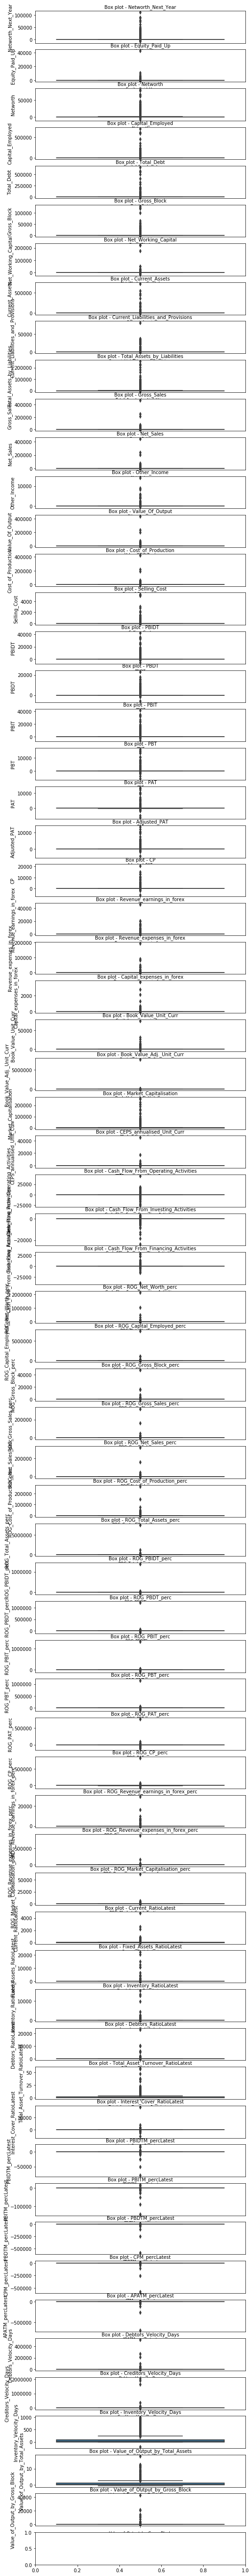

In [22]:
def detect_outlier():
    col_names = list(Company.columns)
    fig, ax = plt.subplots(len(col_names), figsize=(8,100))

    for i, col_val in enumerate(col_names):
        if (col_val == 'default'):
            continue
        sns.boxplot(y=Company[col_val], ax=ax[i])
        ax[i].set_title('Box plot - {}'.format(col_val), fontsize=10)
        ax[i].set_xlabel(col_val, fontsize=8)

    plt.show()
detect_outlier()

As shown in the plots above, there are outliers in the Company dataset almost across all the variables.  One of the prominent methods for treating these outliers is to cap them.  The inter-quartile range is calculated as Q3-Q1.  The upper bound is calculated as Q3+(1.5*IQR) and the lower bound is calculated as Q1-(1.5*IQR).  The data points that are greater than the upper bound can be capped to upper bound and those who are less than the lower bound can be capped to the lower bound.

In [23]:
def check_outlier(col):
    sorted(col)
    Q1,Q3=col.quantile([.25,.75])
    IQR=Q3-Q1
    lower_range= Q1-(1.5 * IQR)
    upper_range= Q3+(1.5 * IQR)
    return lower_range, upper_range

Let's check for the outliers for the following variables.
1. Networth_Next_Year
2. Gross_Sales
3. ROG-PBT_perc

In [24]:
check_outlier(Company['Networth_Next_Year'])

(-175.74125, 303.52875000000006)

In [25]:
check_outlier(Company['Gross_Sales'])

(-359.76875, 603.4612500000001)

In [26]:
check_outlier(Company['ROG_PBT_perc'])

(-196.02375, 216.74624999999997)

In [27]:
Company.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3586 entries, 0 to 3585
Data columns (total 66 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Networth_Next_Year                   3586 non-null   float64
 1   Equity_Paid_Up                       3586 non-null   float64
 2   Networth                             3586 non-null   float64
 3   Capital_Employed                     3586 non-null   float64
 4   Total_Debt                           3586 non-null   float64
 5   Gross_Block                          3586 non-null   float64
 6   Net_Working_Capital                  3586 non-null   float64
 7   Current_Assets                       3586 non-null   float64
 8   Current_Liabilities_and_Provisions   3586 non-null   float64
 9   Total_Assets_by_Liabilities          3586 non-null   float64
 10  Gross_Sales                          3586 non-null   float64
 11  Net_Sales                     

In [28]:
def treat_outlier(x):    
    q25=np.percentile(x,25)
    q75=np.percentile(x,75)        
    IQR=q75-q25
    lower_bound=q25-(1.5*IQR)
    upper_bound=q75+(1.5*IQR)
    return x.apply(lambda y: upper_bound if y > upper_bound else y).apply(lambda y: lower_bound if y < lower_bound else y)

In [29]:
for i in Company:
    if (i == 'default'):
        continue;
    Company[i]=treat_outlier(Company[i])

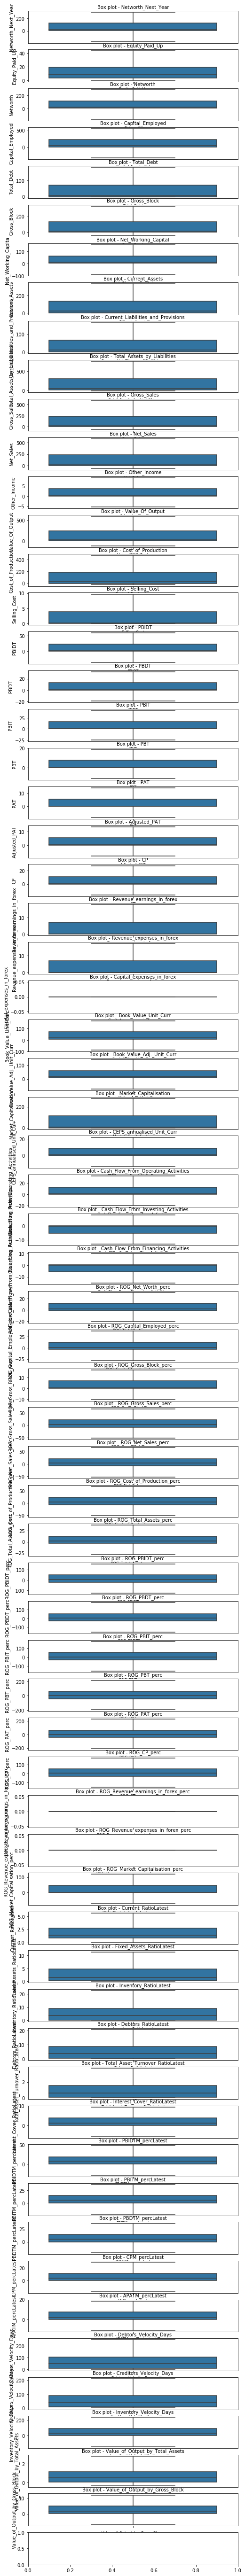

In [30]:
detect_outlier()

As shown in the above plot, the outliers present in the Company data set has been treated and capped, hence, the Company dataset currently has no outliers.

## Univariate, Bivariate Analysis and Heatmaps

As the Company dataset contains around 60+ variables, only some of the selected variables can be considered for performing EDA with univariate analysis, bivariate analysis and for the heatmaps.


In [31]:
def plotHist(data, lbl):
    plt.figure(figsize=(20,10))
    plt.hist(data, color='g')
    plt.axvline(data.mean(), color='m', linewidth=1)
    plt.axvline(data.median(), color='b', linestyle='dashed', linewidth=1)
    plt.axvline(data.mode()[0], color='w', linestyle='dashed', linewidth=1)
    plt.xlabel(lbl)

def plotMeasures(data, lbl):
    mean = data.mean()
    median = data.median()
    mode = data.mode()
    
    print('Mean: ', mean, '\nMedian: ', median, '\nMode: ', mode)
    
    plt.figure(figsize=(10,5))
    plt.hist(data,bins=100,color='lightblue')

    plt.axvline(mean,color='green',label='Mean')    
    plt.axvline(median,color='blue',label='Median')
    plt.axvline(mode[0],color='red',label='Mode1')
    
    plt.xlabel(lbl)  
    plt.ylabel('Frequency')  
    plt.legend()            
    plt.show()

#### Networth - Univariate

Mean:  73.69112102621294 
Median:  18.58 
Mode:  0    287.405
dtype: float64


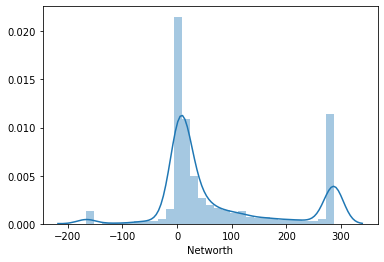

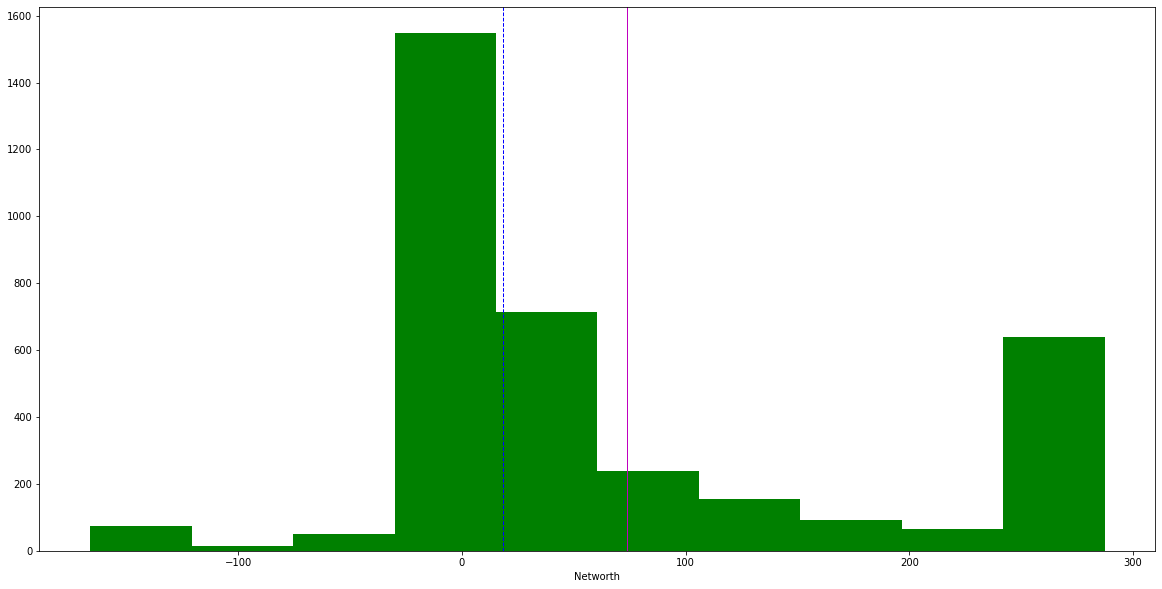

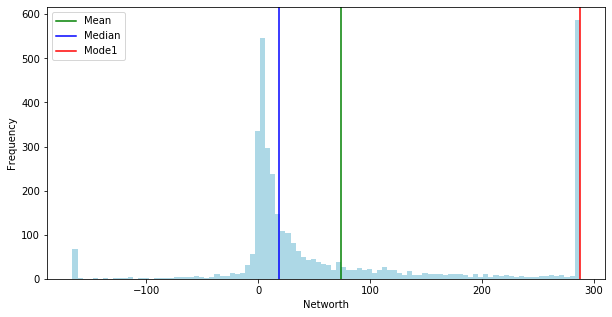

In [32]:
data = Company['Networth']
sns.distplot(data)
plotHist(data, 'Networth')
plotMeasures(data, 'Networth')

From the above plot,
1. Maximum number of observations fall in the 4th bin.
2. The bins 4,5 and 10 have more number of observations when compared to the other bins.
3. The overall distribution of Networth is slightly postive skewed, as the median less than the mean.
4. The mean is 73.69 and the median 18.58

#### Total_Debt - Univariate

Mean:  47.43915225878358 
Median:  7.49 
Mode:  0    0.0
dtype: float64


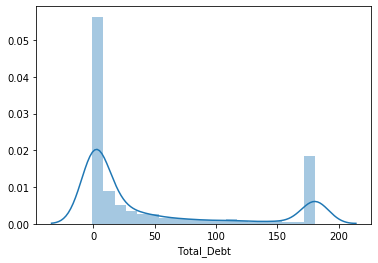

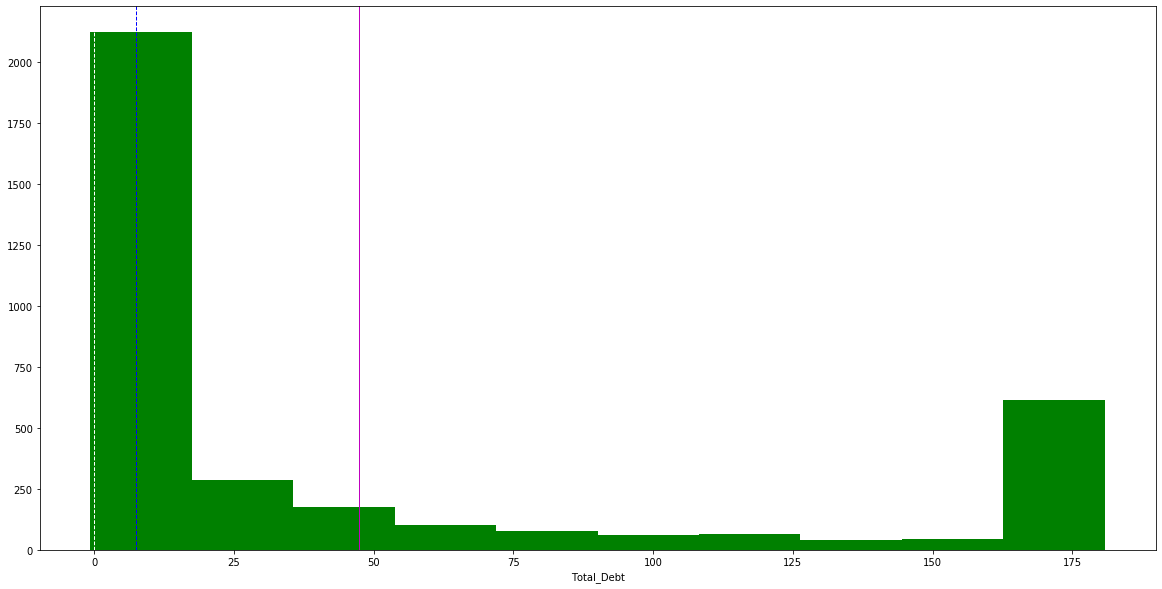

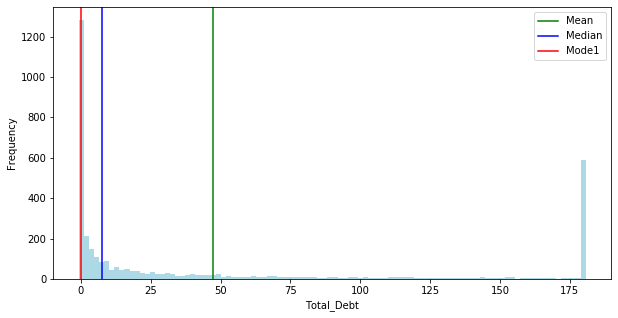

In [33]:
data = Company['Total_Debt']
sns.distplot(data)
plotHist(data, 'Total_Debt')
plotMeasures(data, 'Total_Debt')

From the above plots,
1. Maximum number of observations fall in the 1st bin.
2. The remaining bins have negligible number of observations.
3. The overall distribution is positively skewed as the median is less than the mean.
4. The mean is 47.44 and the median is 7.49.

#### Gross Block - Univariate

Mean:  85.0998633575024 
Median:  15.87 
Mode:  0    328.8825
dtype: float64


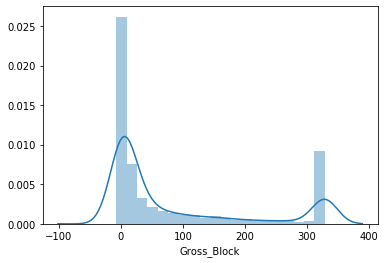

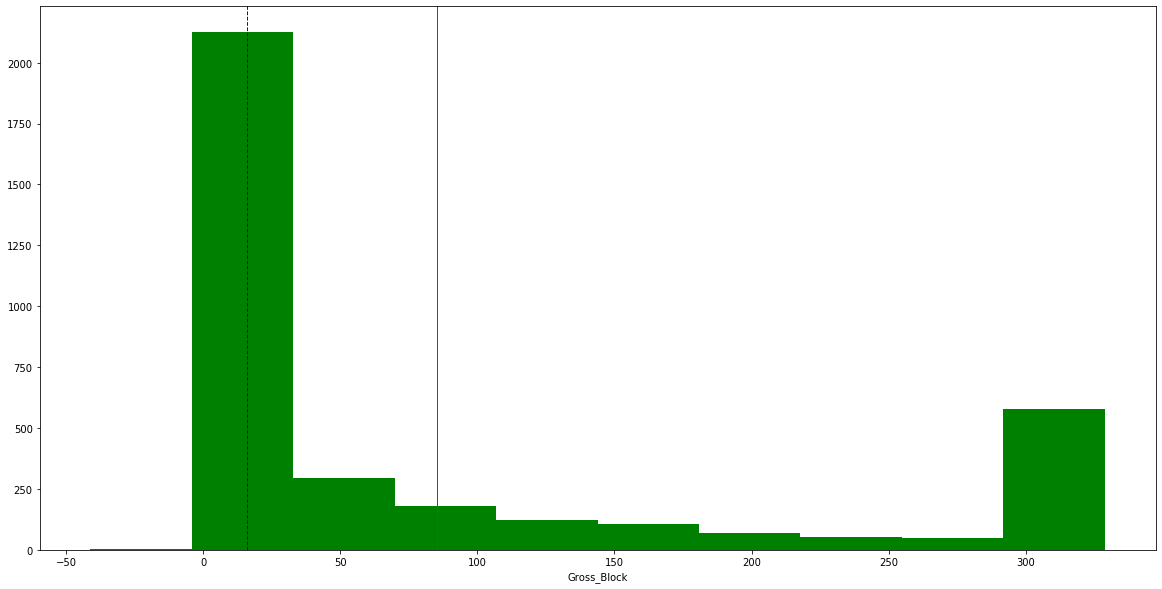

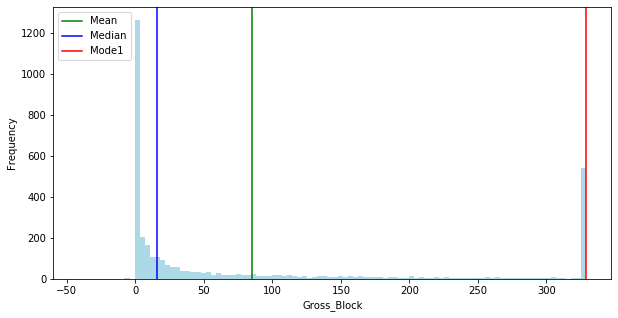

In [34]:
data = Company['Gross_Block']
sns.distplot(data)
plotHist(data, 'Gross_Block')
plotMeasures(data, 'Gross_Block')

As per the above plots,
1. The maximum number of observations fall in the 2nd bin.
2. The remaining bins have only negligible number of observations.
3. The overall distribution is positively skewed.
4. The mean is 85.1 and the median is 15.87

#### Net Sales - Univariate

Mean:  154.1214389291687 
Median:  30.44 
Mode:  0    583.94
dtype: float64


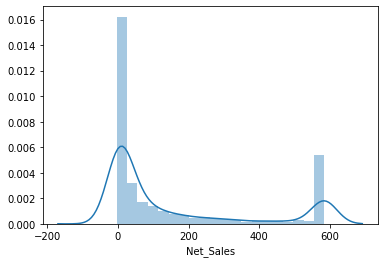

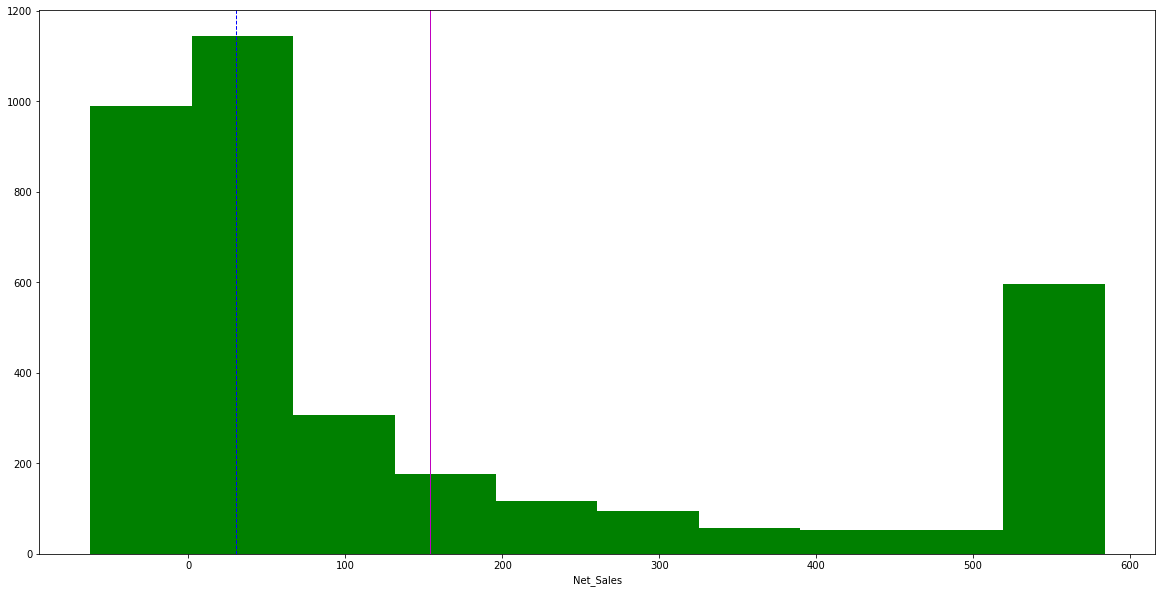

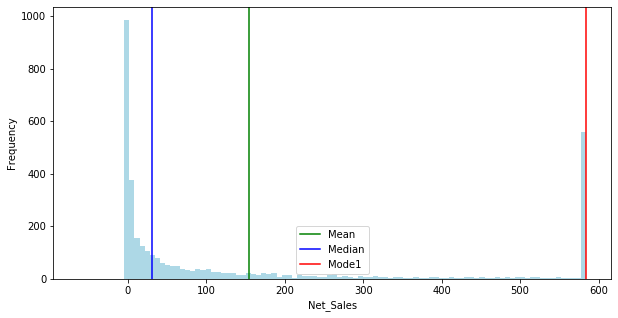

In [35]:
data = Company['Net_Sales']
sns.distplot(data)
plotHist(data, 'Net_Sales')
plotMeasures(data, 'Net_Sales')

From the above plots,
1. The maximum number of observations fall under the 2nd bin.
2. The bins 1 and 2 combinely have most of number of observations when compared to other bins that have only negligible number of observations.
3. The overall distribution is positively skewed.
4. The mean is 154 and the median is 30.

#### PAT - Univariate

Mean:  2.583008923591724 
Median:  0.255 
Mode:  0    13.94
dtype: float64


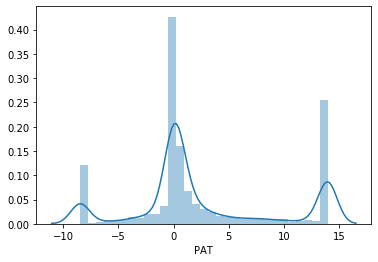

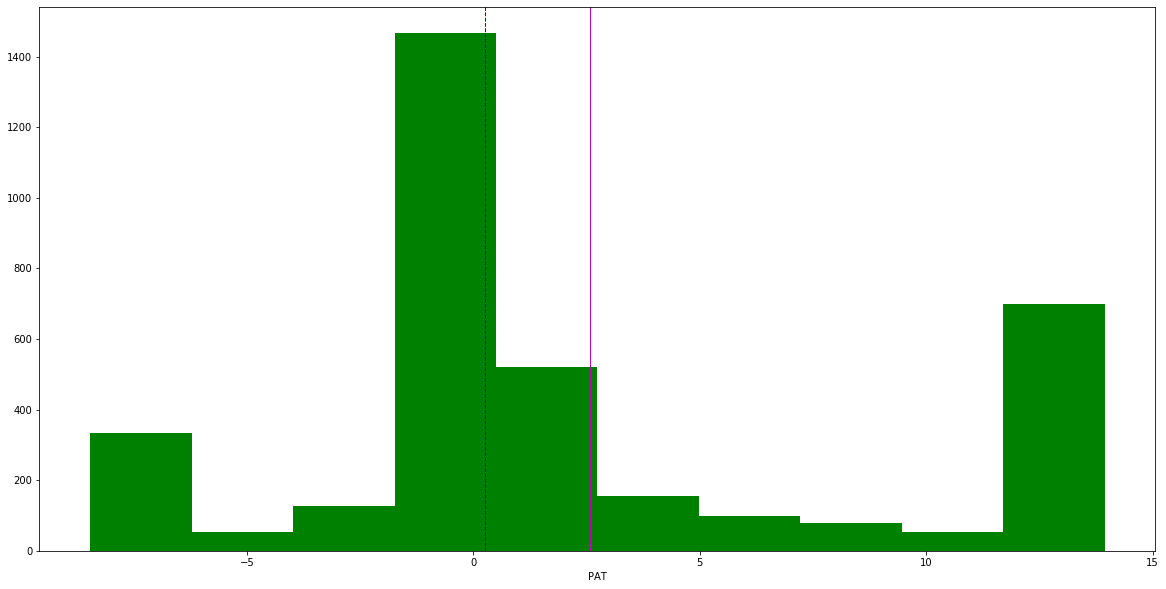

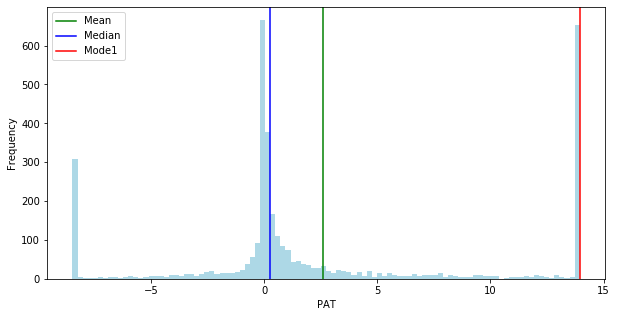

In [36]:
data = Company['PAT']
sns.distplot(data)
plotHist(data, 'PAT')
plotMeasures(data, 'PAT')

From the above plots,
1. The maximum number of observations fall under 4th bin.
2. The overall distribution is positively skewed as the median is less than the mean.
3. The mean is 2.6 and the median is 0.2.

#### ROG-Total_Assets_perc - Univariate

Mean:  4.274318530395977 
Median:  1.475 
Mode:  0    37.20875
dtype: float64


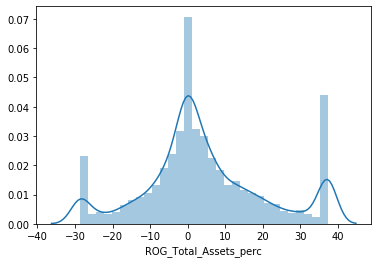

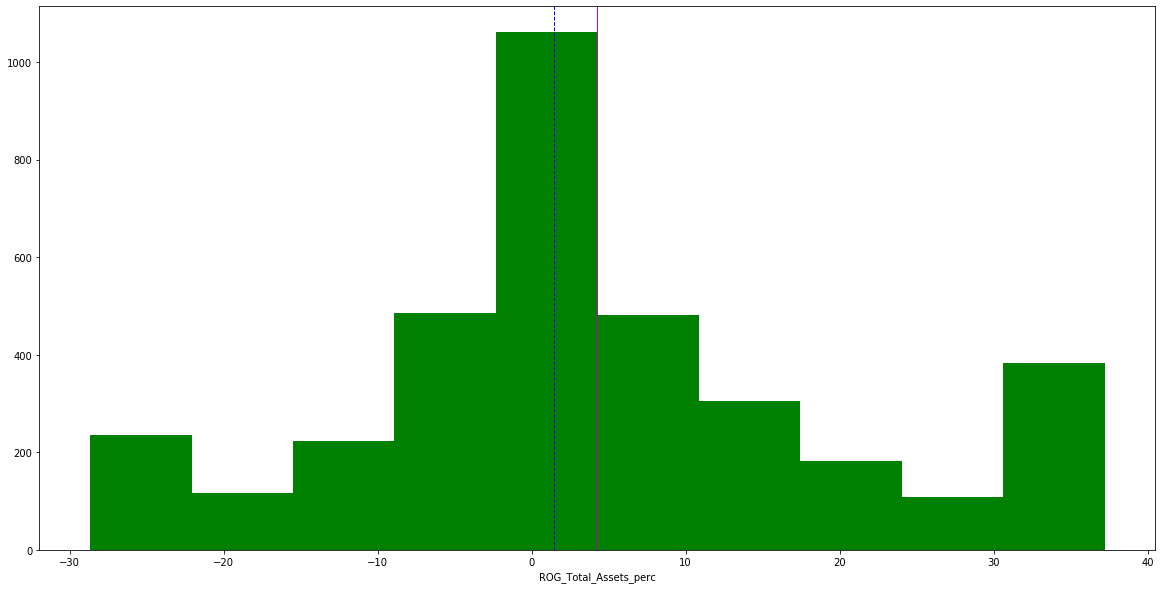

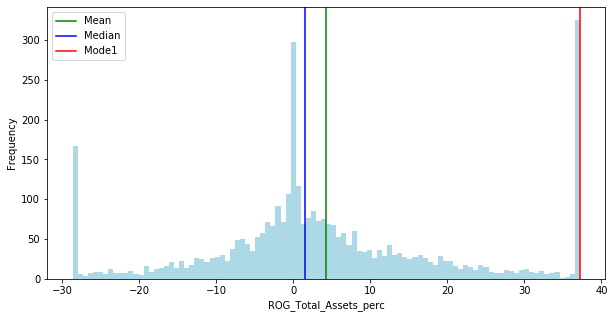

In [37]:
data = Company['ROG_Total_Assets_perc']
sns.distplot(data)
plotHist(data, 'ROG_Total_Assets_perc')
plotMeasures(data, 'ROG_Total_Assets_perc')

From the above plots,
1. The maximum number of observations fall in the 5th bin.
2. The overall distribution is slightly positive-skewed as the median is less than the mean.
3. The mean is 4.3 and the median is 1.5
4. The distribution shows a possibility of outliers presence as well.

#### ROG-PBIDT_perc - Univariate

Mean:  12.605595022308966 
Median:  4.57 
Mode:  0    154.73125
dtype: float64


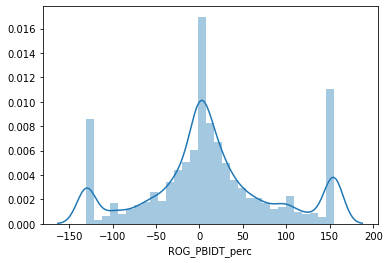

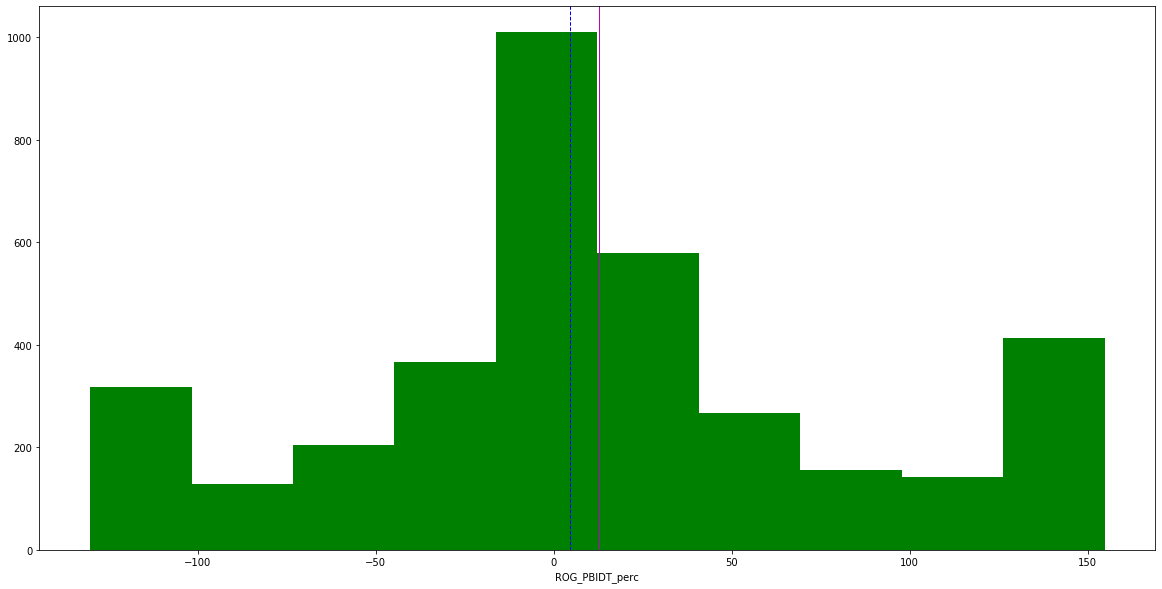

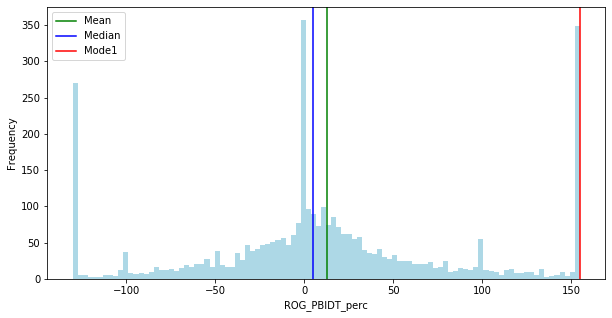

In [38]:
data = Company['ROG_PBIDT_perc']
sns.distplot(data)
plotHist(data, 'ROG_PBIDT_perc')
plotMeasures(data, 'ROG_PBIDT_perc')

From the above plots,
1. The maximum number of observations fall in the 5th bin.
2. The bins 5 and 6 have the majority of observations when compared to all other bins.
3. The overall distribution is slightly positive-skewed, as the median is less than the mean.
4. The mean is 12.6 and the median is 4.6

#### Total_Asset_Turnover_RatioLatest - Univariate

Mean:  0.9903374233128811 
Median:  0.6 
Mode:  0    0.0
dtype: float64


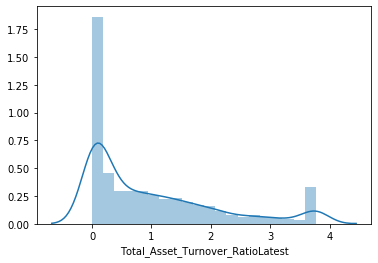

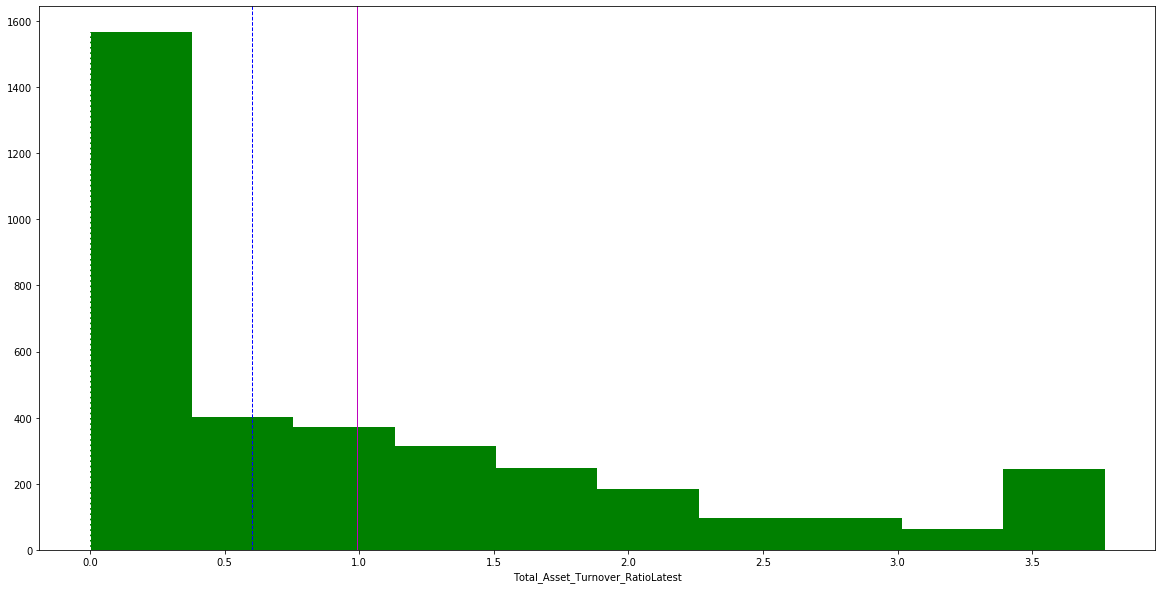

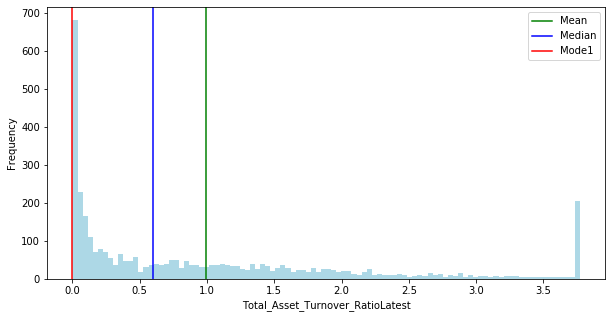

In [39]:
data = Company['Total_Asset_Turnover_RatioLatest']
sns.distplot(data)
plotHist(data, 'Total_Asset_Turnover_RatioLatest')
plotMeasures(data, 'Total_Asset_Turnover_RatioLatest')

From the above plots,
1. The maximum number of observations fall in the 1st bin.
2. The remaining bins have comparatively less number of observations.
3. The overall distribution is slightly positive-skewed as the median is less than the mean.
4. The mean is 0.99 and the median is 0.6

#### Interest_Cover_RatioLatest - Univariate

Mean:  2.078464863357484 
Median:  1.08 
Mode:  0    0.0
dtype: float64


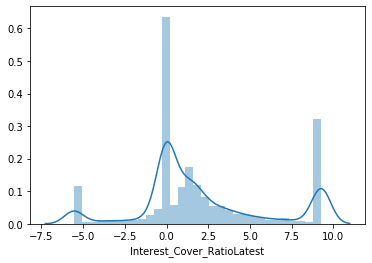

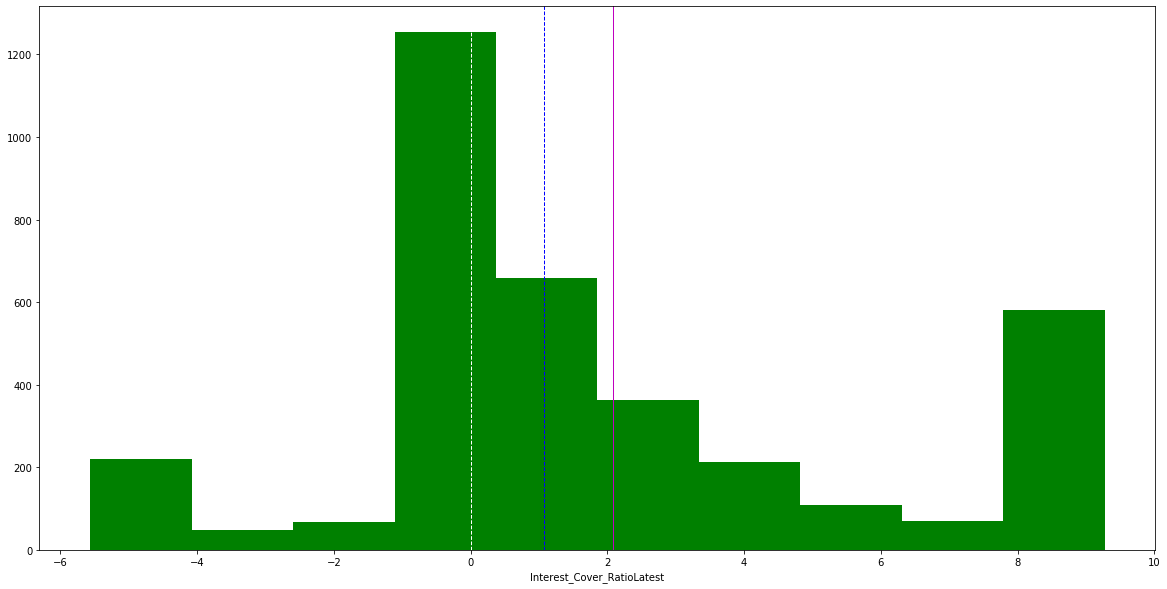

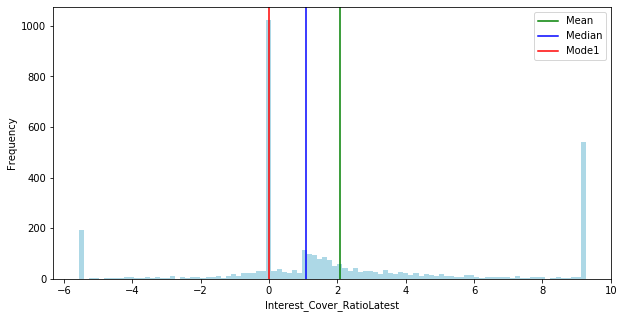

In [40]:
data = Company['Interest_Cover_RatioLatest']
sns.distplot(data)
plotHist(data, 'Interest_Cover_RatioLatest')
plotMeasures(data, 'Interest_Cover_RatioLatest')

From the above plots,
1. The maximum number of observations fall in the 4th bin.
2. The bins 4 and 5 have the majority of obsevations when compared to the other bins.
3. The overall distribution is slightly positive-skewed as the median is less than the mean.
4. The mean is 2.08 and the median is 1.08.

#### Bivariate Analysis

As part of the bivariate analysis, the dataset needs to be studied to understand the impact of various feature variables on the target variable.  The bivariate analysis is mainly conducted to compare the behaviour between any two variables and to find out how one variable impacts the other.

As Networth_Next_Year is the variable that determines whether a company is defaulter or non-defaulter and based on which, we have already included the default target variable in the Company dataset, let's now see how various other variables are related to Networth_Next_Year variable.  As we already determined the default variable, the comparisons need to be made between other variables and default variable as well.

##### Networth Vs Networth_Next_Year(default)

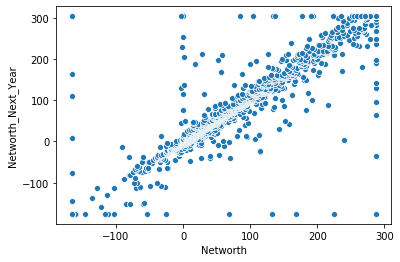

In [41]:
sns.scatterplot(x='Networth', y='Networth_Next_Year', data=Company)

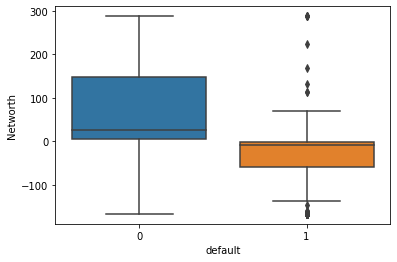

In [42]:
sns.boxplot(x='default', y='Networth', data=Company)

##### Total_Debt Vs Networth_Next_Year(default)

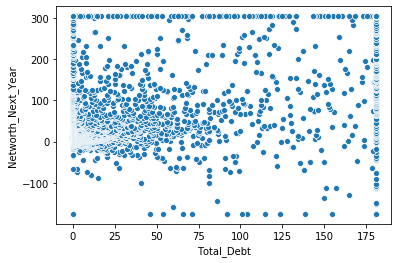

In [43]:
sns.scatterplot(x='Total_Debt', y='Networth_Next_Year', data=Company)

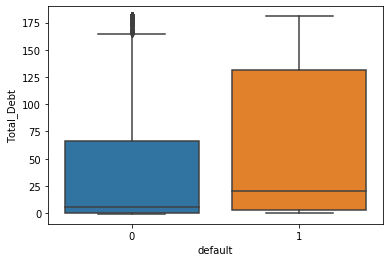

In [44]:
sns.boxplot(x='default', y='Total_Debt', data=Company)

##### Gross_Block Vs Networth_Next_Year(default)

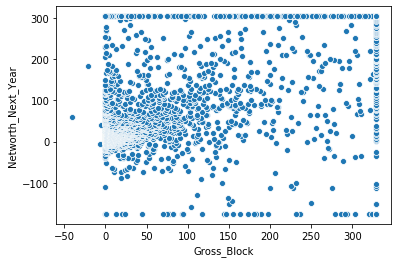

In [45]:
sns.scatterplot(x='Gross_Block', y='Networth_Next_Year', data=Company)

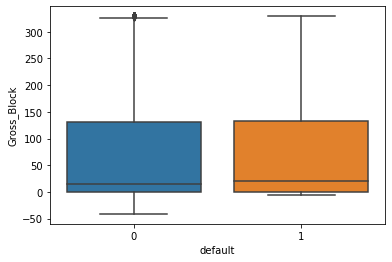

In [46]:
sns.boxplot(x='default', y='Gross_Block', data=Company)

##### Total_Assets_to_Liab Vs Networth_Next_Year(default)

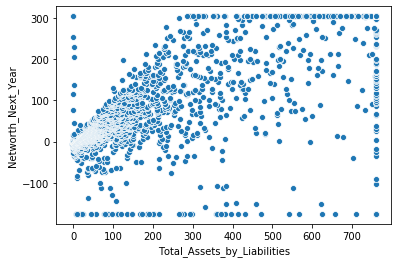

In [47]:
sns.scatterplot(x='Total_Assets_by_Liabilities', y='Networth_Next_Year', data=Company)

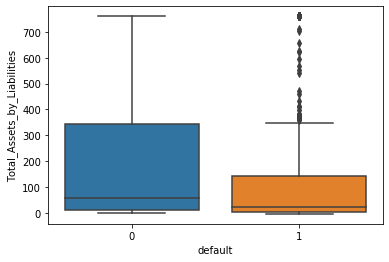

In [48]:
sns.boxplot(x='default', y='Total_Assets_by_Liabilities', data=Company)

##### Net_Sales Vs Networth_Next_Year(default)

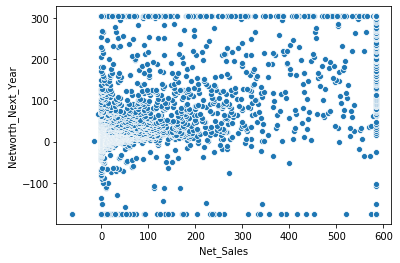

In [49]:
sns.scatterplot(x='Net_Sales', y='Networth_Next_Year', data=Company)

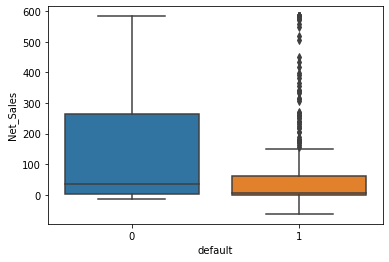

In [50]:
sns.boxplot(x='default', y='Net_Sales', data=Company)

##### PBIDT Vs Networth_Next_Year(default)

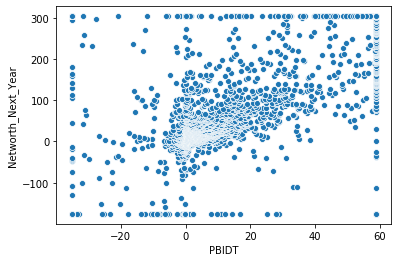

In [51]:
sns.scatterplot(x='PBIDT', y='Networth_Next_Year', data=Company)

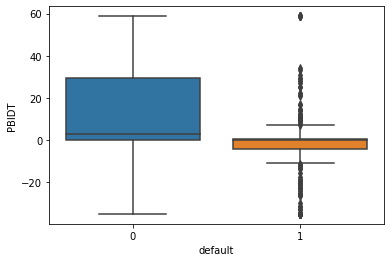

In [52]:
sns.boxplot(x='default', y='PBIDT', data=Company)

##### Total_Asset_Turnover_RatioLatest Vs Networth_Next_Year(default)

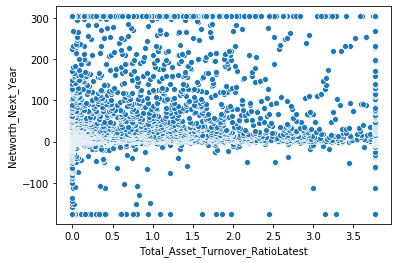

In [53]:
sns.scatterplot(x='Total_Asset_Turnover_RatioLatest', y='Networth_Next_Year', data=Company)

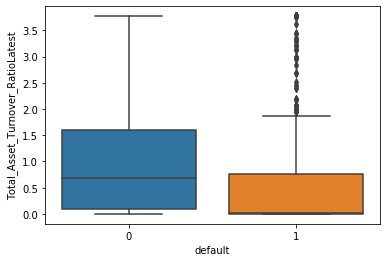

In [54]:
sns.boxplot(x='default', y='Total_Asset_Turnover_RatioLatest', data=Company)

##### Bivariate Analysis Summary

From the various bivariate plots above,
1. The networth is clearly on higher side for non-defaulters than the defaulters.  Also, the relationship between Networth and Networth_Next_Year is on the linear side as expected.
2. During the comparison between Total_Debt variable and the default (Networth_Next_Year) variable, it is clear that the default companies have more total debt than the non-defaulter companies.
3. From the bivariate plot that shows the relationship between the variables Gross_Block and default,  it is observed that the Gross_Block is more or less equal between defaulter and non-defaulter companies.  This could be an indication that both default and non-default companies have equal assets but some other variables could be playing the significant role in making specific companies as defaulters while others not, like assets are under-valued etc.
4. The Total_Assets_By_Liabilities ratio is clearly high for non-defaulter companies than the defaulter companies.  This is one of the expected observations and potential indication that the defaulter companies have more liabilities than non-defaulter companies though both have more or less equal on Gross_Block.
5. The Net_Sales is clearly on the higher side for non-defaulter companies than the defaulter companies.
6. The remaining plots that compare PBIDT and assets turnover ratio with default variable also clearly shows that most of the non-defaulter companies have higher PBIDT and total assets turnover ration when compared to the defaulter companies.

#### Heatmaps

The heatmaps are one of the important plots that show how each variable in a dataset is correlated with other variables.  This includes both magnitude of the correlation and direction of correlation that whether the two variables are positively correlated or negativey correlated.
Let's look into the heatmap of the Company dataset to understand correlation across the variables.

In [55]:
Company_copy1 = Company.drop('default', axis=1)

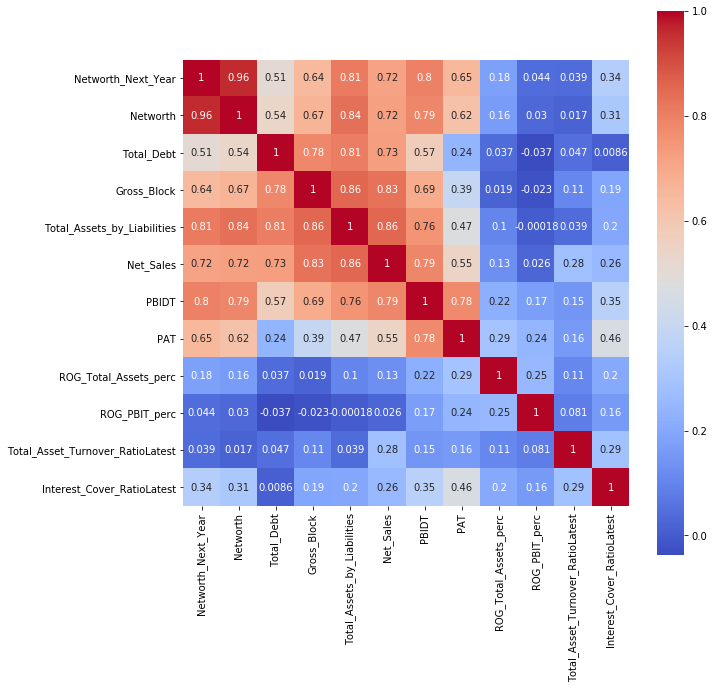

In [56]:
cont = ['Networth_Next_Year','Networth','Total_Debt','Gross_Block','Total_Assets_by_Liabilities','Net_Sales',\
        'PBIDT','PAT','ROG_Total_Assets_perc','ROG_PBIT_perc','Total_Asset_Turnover_RatioLatest',\
       'Interest_Cover_RatioLatest']

plt.figure(figsize=(10,10))  
p=sns.heatmap(Company_copy1[cont].corr(), annot=True, cmap='coolwarm', square=True)

From the correlation heatmap given above,
1. There is a strong correlation shown by the Total_Debt variable with other variables Gross_Block, Total_Assets_by_Liabilities, and Net_Sales.
2. The variable Gross_Block shows strong correlation with Total_Assets_by_Liabilities and Net_Sales.
3. The Total_Assets_by_Liabilities is showing high correletion with Networth_Next_Year, Networth, Total_Debt, Gross_Block and Net_Sales.
4. The variables Net_Sales and PBIDT also showing high correlation with Networth_Next_Year.
5. On the negative side of the correlation, the variables Total_Debt and ROG-PBIT_perc are showing slight correlation.
5. The remaining variables are not showing any high correlations with any of the other variables.

## Train-Test Split

The company dataset is split into train dataset and test dataset using the split ratio of 67(train):33(test).  The random state value of 42 is used for the split as well.

In [57]:
from sklearn.model_selection import train_test_split

In [58]:
X = Company.drop(['default','Networth_Next_Year'], axis=1)
y = Company['default']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.33,random_state=42,stratify=Company['default'])

Company_train = pd.concat([X_train,y_train], axis=1)
Company_test = pd.concat([X_test,y_test], axis=1)


In [59]:
print('The number of observations in train: ',X_train.shape[0],'\n''The number of observations in test: ',X_test.shape[0])

The number of observations in train:  2402 
The number of observations in test:  1184


# Modelling

As we are done with Exploratory Data Analysis, missing values treatment, outliers detection and treatment, along with train-test split of the Company dataset, let's start with model building.

## Build Logistic Regression Model on most important variables on Train Dataset

### Check for Multi-collinearity

Before starting the model-building exercise, let's look at the problem of multi-collinearity.  Multicollinearity occurs when two or more independent variables are highly correlated with each other in a regression model.  This multicollinearity between the independent variables will have adverse impact on the models, hence, this dataset needs to be analyzed for any multicollinearity across several independent variables and if present, it needs to be treated accordingly.  In most of the cases, the variables that contribute to high degree of multicollinearity are generally removed from the dataset before model building.

The variance inflation factor is one of the useful measures to detect multicollinearity across independent variables in a dataset.  If variance inflation factor of a variable is greater than 5, then, that specific variable contributes to multicollinearity, hence, the variable can be removed from the dataset before model-building.

In [60]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [61]:
def calc_vif(X):
    vif = pd.DataFrame()
    vif["Variables"] = X.columns
    vif["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return(vif)

In [62]:
VIF_frame = calc_vif(X_train).sort_values(by="VIF")

In [63]:
VIF_frame.dropna(inplace=True)

In [64]:
VIF_frame[VIF_frame['VIF'] < 5]

,Variables,VIF
34,ROG_Gross_Block_perc,1.592639
47,ROG_Market_Capitalisation_perc,1.710300
61,Inventory_Velocity_Days,1.924136
37,ROG_Cost_of_Production_perc,2.067402
60,Creditors_Velocity_Days,2.325263
48,Current_RatioLatest,2.386817
50,Inventory_RatioLatest,2.419741
59,Debtors_Velocity_Days,2.484535
51,Debtors_RatioLatest,2.554689
30,Cash_Flow_From_Investing_Activities,2.624114


As we now have the VIF value for all of the variables of Company dataset, the variables with VIF value of less than 5 can only be considered for any further model building.  The variables with VIF value of more than 5 need not be considered for model building due to multicollinearity.

### Logistic Regression

As mentioned in the above section, let's consider only the variables with VIF value of less than 5 for model building.

In [65]:
import statsmodels.formula.api as SM

In [66]:
f_1 = 'default ~ ROG_Gross_Block_perc + ROG_Market_Capitalisation_perc + Inventory_Velocity_Days + ROG_Cost_of_Production_perc + Creditors_Velocity_Days + Current_RatioLatest + Inventory_RatioLatest + Debtors_Velocity_Days + Debtors_RatioLatest + Cash_Flow_From_Investing_Activities + Interest_Cover_RatioLatest + Cash_Flow_From_Financing_Activities + ROG_Net_Worth_perc + Revenue_earnings_in_forex + ROG_Total_Assets_perc + Revenue_expenses_in_forex + Cash_Flow_From_Operating_Activities + ROG_Capital_Employed_perc + Other_Income + Market_Capitalisation + Equity_Paid_Up + Selling_Cost'

In [67]:
model_1 = SM.logit(formula=f_1, data=Company_train).fit()
model_1

Optimization terminated successfully.
         Current function value: 0.209977
         Iterations 8


In [68]:
model_1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                default   No. Observations:                 2402
Model:                          Logit   Df Residuals:                     2379
Method:                           MLE   Df Model:                           22
Date:                Tue, 22 Dec 2020   Pseudo R-squ.:                  0.3859
Time:                        17:05:42   Log-Likelihood:                -504.36
converged:                       True   LL-Null:                       -821.36
Covariance Type:            nonrobust   LLR p-value:                6.253e-120
=======================================================================================================
                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
Intercept                              -0.6528      0.181     -3.602      0.000      -1.008      -0.298
ROG_Gross_Block_perc                   -0.0323      0.015     -2.198      0.028      -0.061      -0.003
ROG_Market_Capitalisation_perc          0.0006      0.002      0.314      0.753      -0.003       0.005
Inventory_Velocity_Days                -0.0020      0.001     -1.623      0.105      -0.004       0.000
ROG_Cost_of_Production_perc            -0.0081      0.003     -3.108      0.002      -0.013      -0.003
Creditors_Velocity_Days                 0.0037      0.001      3.306      0.001       0.002       0.006
Current_RatioLatest                    -0.6813      0.079     -8.651      0.000      -0.836      -0.527
Inventory_RatioLatest                  -0.0135      0.014     -0.978      0.328      -0.041       0.014
Debtors_Velocity_Days                  -0.0041      0.001     -3.856      0.000      -0.006      -0.002
Debtors_RatioLatest                    -0.0198      0.015     -1.320      0.187      -0.049       0.010
Cash_Flow_From_Investing_Activities     0.0034      0.025      0.137      0.891      -0.046       0.053
Interest_Cover_RatioLatest             -0.1891      0.032     -5.946      0.000      -0.251      -0.127
Cash_Flow_From_Financing_Activities    -0.0080      0.023     -0.347      0.729      -0.054       0.037
ROG_Net_Worth_perc                     -0.0440      0.009     -5.115      0.000      -0.061      -0.027
Revenue_earnings_in_forex              -0.0271      0.019     -1.403      0.161      -0.065       0.011
ROG_Total_Assets_perc                  -0.0110      0.008     -1.366      0.172      -0.027       0.005
Revenue_expenses_in_forex               0.0387      0.020      1.909      0.056      -0.001       0.078
Cash_Flow_From_Operating_Activities    -0.0155      0.013     -1.198      0.231      -0.041       0.010
ROG_Capital_Employed_perc              -0.0027      0.008     -0.339      0.735      -0.019       0.013
Other_Income                            0.0263      0.038      0.700      0.484      -0.047       0.100
Market_Capitalisation                  -0.0095      0.002     -5.166      0.000      -0.013      -0.006
Equity_Paid_Up                          0.0141      0.007      1.890      0.059      -0.001       0.029
Selling_Cost                           -0.0054      0.044     -0.123      0.902      -0.091       0.081
=======================================================================================================
"""

In [69]:
print('The adjusted pseudo R-square value is',1 - ((model_1.llf - model_1.df_model)/model_1.llnull))

The adjusted pseudo R-square value is 0.35915347611449633


The adjusted pseudo R-square value is less than the pseudo R-square value which means that there are still insignificant variables present in the model.  Let's try to remove the variables with p-value of greater than 0.05 and try building the model again.

In [70]:
f_2 = 'default ~ ROG_Gross_Block_perc + ROG_Cost_of_Production_perc + Creditors_Velocity_Days + Current_RatioLatest + Debtors_Velocity_Days + Interest_Cover_RatioLatest + ROG_Net_Worth_perc + Market_Capitalisation'

In [71]:
model_2 = SM.logit(formula=f_2, data=Company_train).fit()
model_2

Optimization terminated successfully.
         Current function value: 0.215355
         Iterations 8


In [72]:
model_2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                default   No. Observations:                 2402
Model:                          Logit   Df Residuals:                     2393
Method:                           MLE   Df Model:                            8
Date:                Tue, 22 Dec 2020   Pseudo R-squ.:                  0.3702
Time:                        17:05:42   Log-Likelihood:                -517.28
converged:                       True   LL-Null:                       -821.36
Covariance Type:            nonrobust   LLR p-value:                4.139e-126
===============================================================================================
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -0.7349      0.154     -4.770      0.000      -1.037      -0.433
ROG_Gross_Block_perc           -0.0441      0.014     -3.251      0.001      -0.071      -0.018
ROG_Cost_of_Production_perc    -0.0086      0.003     -3.349      0.001      -0.014      -0.004
Creditors_Velocity_Days         0.0039      0.001      3.521      0.000       0.002       0.006
Current_RatioLatest            -0.7028      0.082     -8.615      0.000      -0.863      -0.543
Debtors_Velocity_Days          -0.0040      0.001     -4.032      0.000      -0.006      -0.002
Interest_Cover_RatioLatest     -0.2011      0.031     -6.504      0.000      -0.262      -0.140
ROG_Net_Worth_perc             -0.0528      0.007     -7.501      0.000      -0.067      -0.039
Market_Capitalisation          -0.0081      0.001     -5.708      0.000      -0.011      -0.005
===============================================================================================
"""

In [73]:
print('The adjusted pseudo R-square value is',1 - ((model_2.llf - model_2.df_model)/model_2.llnull))

The adjusted pseudo R-square value is 0.36047044052521227


Now, we can see that the adjusted pseudo R-square value is closer to pseudo R-square value which means that there are very minimal insignificant variables only present in the model.  Also, from model summary, it is clear that the probability is less than 0.05 for all the variables that means no variables is insignificant.  Now, let's predict using this model on the train and test datasets.

In [74]:
y_prob_pred_train = model_2.predict(Company_train)
y_prob_pred_train

3221    0.001138
2699    0.011973
881     0.085709
100     0.394239
867     0.017070
          ...   
736     0.235976
826     0.008696
1497    0.000512
327     0.494349
2969    0.000724
Length: 2402, dtype: float64

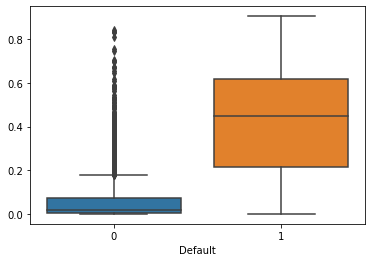

In [75]:
sns.boxplot(x=Company_train['default'], y=y_prob_pred_train)
plt.xlabel('Default');

From the above plot, we have to derive at a cut-off which provides us most reasonable descriptive power of the model.  Let's take the initial cut-off as 0.1. 

After several iterations of cut-off with different values, the optimal value has been found

In [76]:
fpr, tpr, thresholds = metrics.roc_curve(Company_train['default'],y_prob_pred_train)

optimal_idx = np.argmax(tpr - fpr)
optimal_threshold = thresholds[optimal_idx]
optimal_threshold

0.1914759365511688

In [77]:
y_class_pred=[]
for i in range(0,len(y_prob_pred_train)):
    if np.array(y_prob_pred_train)[i]>optimal_threshold:
        a=1
    else:
        a=0
    y_class_pred.append(a)

In [78]:
def model_eval_params(labels, predict):
    metric = metrics.classification_report(labels, predict, output_dict=True)
    df = pd.DataFrame(metric).transpose()
    recall=round(df.loc["1"][1],2)
    precision = round(df.loc["1"][0],2)
    acc = round(df.loc["accuracy"][2],2)
    return recall,precision,acc

#Function for auc-roc parameters
#Function for auc-roc
def auc_roc(probs, dataset_labels):
    # calculate AUC
    auc = metrics.roc_auc_score(dataset_labels, probs)
    print('AUC: %.3f' % auc)
    # calculate roc curve
    fpr, tpr, thresholds = metrics.roc_curve(dataset_labels, probs)
    plt.plot([0, 1], [0, 1], linestyle='--')
    # plot the roc curve for the model
    plt.plot(fpr, tpr)
    return round(auc,2),fpr,tpr

#Function for Accuracy Score, Confusion Matrix, Classification Report
def as_cm_cr(model, dataset, labels, predict, algo_label, train_test):
    cm = metrics.confusion_matrix(labels, predict)
    print("{} - Confusion Matrix({} dataset):\n {}".format(algo_label, train_test, cm))
    cr = metrics.classification_report(labels, predict);
    print("{} - Classification Report({} dataset): \n {}".format(algo_label, train_test, cr))
    return

Logistic Regression - Confusion Matrix(Train dataset):
 [[1895  248]
 [  60  199]]
Logistic Regression - Classification Report(Train dataset): 
               precision    recall  f1-score   support

           0       0.97      0.88      0.92      2143
           1       0.45      0.77      0.56       259

    accuracy                           0.87      2402
   macro avg       0.71      0.83      0.74      2402
weighted avg       0.91      0.87      0.89      2402

AUC: 0.898


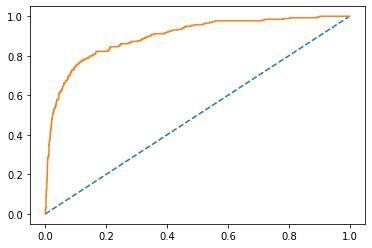

In [80]:
as_cm_cr(model_2, Company_train, Company_train['default'], y_class_pred, 'Logistic Regression', 'Train')
lr_auc_train,lr_fpr_train,lr_tpr_train = auc_roc(y_prob_pred_train, Company_train['default'])
lr_recall_train, lr_prec_train, lr_acc_train = model_eval_params(Company_train['default'], y_class_pred)

In [81]:
lr_train_metrics = [lr_acc_train, lr_recall_train, lr_prec_train, lr_auc_train]
print(lr_recall_train,lr_prec_train,lr_acc_train,lr_auc_train)

0.77 0.45 0.87 0.9


## Validate the Model on Test Dataset and state the performance matrices

### Logistic Regression - Model validation on Test Dataset

As the logistic regression model has been built, validated and performance metrics have been successfully retrieved for train dataset, let's now validate the same model for test dataset.

In [82]:
y_prob_pred_test = model_2.predict(Company_test)
y_prob_pred_test

251     0.337466
3493    0.008926
3062    0.000914
2383    0.054410
1678    0.006855
          ...   
1320    0.009302
2665    0.012770
772     0.199470
3488    0.001298
2955    0.018819
Length: 1184, dtype: float64

In [83]:
y_class_pred=[]
for i in range(0,len(y_prob_pred_test)):
    if np.array(y_prob_pred_test)[i]>optimal_threshold:
        a=1
    else:
        a=0
    y_class_pred.append(a)

Logistic Regression - Confusion Matrix(Test dataset):
 [[930 126]
 [ 34  94]]
Logistic Regression - Classification Report(Test dataset): 
               precision    recall  f1-score   support

           0       0.96      0.88      0.92      1056
           1       0.43      0.73      0.54       128

    accuracy                           0.86      1184
   macro avg       0.70      0.81      0.73      1184
weighted avg       0.91      0.86      0.88      1184

AUC: 0.898


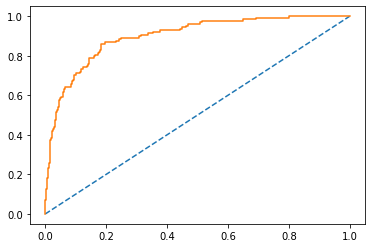

In [84]:
as_cm_cr(model_2, Company_test, Company_test['default'], y_class_pred, 'Logistic Regression', 'Test')
lr_auc_test,lr_fpr_test,lr_tpr_test = auc_roc(y_prob_pred_test, Company_test['default'])
lr_recall_test, lr_prec_test, lr_acc_test = model_eval_params(Company_test['default'], y_class_pred)

In [85]:
lr_test_metrics = [lr_acc_test, lr_recall_test, lr_prec_test, lr_auc_test]
print(lr_recall_test,lr_prec_test,lr_acc_test,lr_auc_test)

0.73 0.43 0.86 0.9


As shown above, the logistic regression model performance metrics like recall, accuracy and AUC score are consistent between train dataset and test dataset.  This clearly shows the model neither overfits nor underfits and hence, reasonably a stable model.

### Performance Metrics

The performance metrics for the logistic regression model is given below

In [86]:
lr_index = ['Accuracy', 'Recall', 'Precision', 'AUC']
lr_metrics = pd.DataFrame({'LR Train': lr_train_metrics, 'LR Test': lr_test_metrics}, index=lr_index)
lr_metrics

,LR Train,LR Test
Accuracy,0.87,0.86
Recall,0.77,0.73
Precision,0.45,0.43
AUC,0.90,0.90


## Build a Random Forest Model on Train Dataset

As we completed the model building using logistic regression for the Company dataset, let's now try building the model using random forest.  The random forest is a tree based model.

In [87]:
from sklearn.ensemble import RandomForestClassifier

In [88]:
rf_model = RandomForestClassifier(n_estimators=500, max_depth=8, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=8, n_estimators=500, random_state=42)

In [89]:
y_pred_train = rf_model.predict(X_train)

In [90]:
as_cm_cr(rf_model, X_train, y_train, y_pred_train, 'Random Forest', 'Train')

Random Forest - Confusion Matrix(Train dataset):
 [[2143    0]
 [   0  259]]
Random Forest - Classification Report(Train dataset): 
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      2143
           1       1.00      1.00      1.00       259

    accuracy                           1.00      2402
   macro avg       1.00      1.00      1.00      2402
weighted avg       1.00      1.00      1.00      2402



As shown above, this random forest model clearly overfits for the train dataset.  It does not make any error at all.  Now, let's try tuning the random forest model parameters with further iterations using grid search 

In [91]:
from sklearn.model_selection import GridSearchCV

In [92]:
param_grid = {
    'max_depth': [7, 8],
    'max_features': [4,5,6],
    'min_samples_leaf': [20, 25],
    'min_samples_split': [60, 75],
    'n_estimators': [101, 301]
}

rf_model = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(estimator = rf_model, param_grid = param_grid, cv = 10)
grid_search.fit(X_train, y_train)

GridSearchCV(cv=10, estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [7, 8], 'max_features': [4, 5, 6],
                         'min_samples_leaf': [20, 25],
                         'min_samples_split': [60, 75],
                         'n_estimators': [101, 301]})

In [93]:
grid_search.best_params_

{'max_depth': 7,
 'max_features': 5,
 'min_samples_leaf': 20,
 'min_samples_split': 75,
 'n_estimators': 301}

In [94]:
best_grid = grid_search.best_estimator_
best_grid

RandomForestClassifier(max_depth=7, max_features=5, min_samples_leaf=20,
                       min_samples_split=75, n_estimators=301, random_state=42)

In [95]:
y_pred_train = best_grid.predict(X_train)
probs = best_grid.predict_proba(X_train)
y_prob_pred_train = probs[:,1]

Random Forest - Confusion Matrix(Train dataset):
 [[2125   18]
 [  28  231]]
Random Forest - Classification Report(Train dataset): 
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      2143
           1       0.93      0.89      0.91       259

    accuracy                           0.98      2402
   macro avg       0.96      0.94      0.95      2402
weighted avg       0.98      0.98      0.98      2402

AUC: 0.995


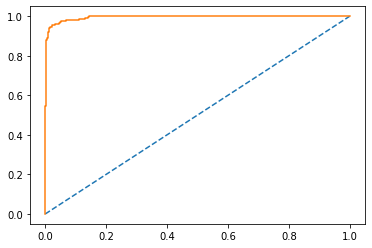

In [96]:
as_cm_cr(best_grid, X_train, y_train, y_pred_train, 'Random Forest', 'Train')
rf_auc_train,rf_fpr_train,rf_tpr_train = auc_roc(y_prob_pred_train, y_train)
rf_recall_train, rf_prec_train, rf_acc_train = model_eval_params(y_train, y_pred_train)

In [97]:
rf_train_metrics = [rf_acc_train, rf_recall_train, rf_prec_train, rf_auc_train]
print(rf_recall_train,rf_prec_train,rf_acc_train,rf_auc_train)

0.89 0.93 0.98 0.99


## Validate the Random Forest Model on test Dataset and state the performance matrices

### Random Forest Classifier - Model validation on Test Dataset

As the Random Forest model has been built, validated and performance metrics have been successfully retrieved for train dataset, let's now validate the same model for test dataset.

In [98]:
y_pred_test = best_grid.predict(X_test)
probs = best_grid.predict_proba(X_test)
y_prob_pred_test = probs[:,1]

Random Forest - Confusion Matrix(Test dataset):
 [[1046   10]
 [  17  111]]
Random Forest - Classification Report(Test dataset): 
               precision    recall  f1-score   support

           0       0.98      0.99      0.99      1056
           1       0.92      0.87      0.89       128

    accuracy                           0.98      1184
   macro avg       0.95      0.93      0.94      1184
weighted avg       0.98      0.98      0.98      1184

AUC: 0.988


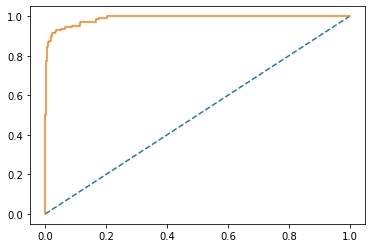

In [99]:
as_cm_cr(best_grid, X_test, y_test, y_pred_test, 'Random Forest', 'Test')
rf_auc_test,rf_fpr_test,rf_tpr_test = auc_roc(y_prob_pred_test, y_test)
rf_recall_test, rf_prec_test, rf_acc_test = model_eval_params(y_test, y_pred_test)

In [100]:
rf_test_metrics = [rf_acc_test, rf_recall_test, rf_prec_test, rf_auc_test]
print(rf_recall_test,rf_prec_test,rf_acc_test,rf_auc_test)

0.87 0.92 0.98 0.99


As shown above, the random forest model performance metrics like recall, accuracy and AUC score are consistent between train dataset and test dataset. This clearly shows the model neither overfits nor underfits and hence, reasonably a stable model.

### Performance Metrics

The performance metrics for the random forest model is given below

In [101]:
rf_index = ['Accuracy', 'Recall', 'Precision', 'AUC']
rf_metrics = pd.DataFrame({'RF Train': rf_train_metrics, 'RF Test': rf_test_metrics}, index=rf_index)
rf_metrics

,RF Train,RF Test
Accuracy,0.98,0.98
Recall,0.89,0.87
Precision,0.93,0.92
AUC,0.99,0.99


## Build an LDA Model on Train Dataset

LDA (Linear Discriminant Analysis) is one of the ways to solve the classification problem and it generally performs better than logistic regression when the target classes are well-separated.  Let's try building a model using LDA approach for the Company dataset.

In [102]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [103]:
lda_model = LinearDiscriminantAnalysis()
lda_model.fit(X_train, y_train)

LinearDiscriminantAnalysis()

In [104]:
y_pred_train = lda_model.predict(X_train)
probs = lda_model.predict_proba(X_train)
y_prob_pred_train = probs[:,1]

LDA - Confusion Matrix(Train dataset):
 [[2113   30]
 [ 117  142]]
LDA - Classification Report(Train dataset): 
               precision    recall  f1-score   support

           0       0.95      0.99      0.97      2143
           1       0.83      0.55      0.66       259

    accuracy                           0.94      2402
   macro avg       0.89      0.77      0.81      2402
weighted avg       0.93      0.94      0.93      2402

AUC: 0.958


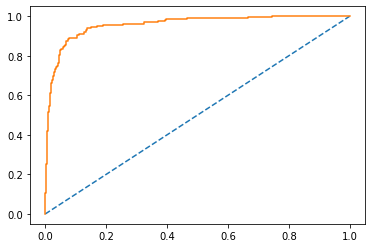

In [105]:
as_cm_cr(lda_model, X_train, y_train, y_pred_train, 'LDA', 'Train')
lda_auc_train,lda_fpr_train,lda_tpr_train = auc_roc(y_prob_pred_train, y_train)
lda_recall_train, lda_prec_train, lda_acc_train = model_eval_params(y_train, y_pred_train)

In [106]:
lda_train_metrics = [lda_acc_train, lda_recall_train, lda_prec_train, lda_auc_train]
print(lda_recall_train,lda_prec_train,lda_acc_train,lda_auc_train)

0.55 0.83 0.94 0.96


## Validate the LDA Model on test Dataset and state the performance metrics

### LDA - Model Validation on Test Dataset

As the LDA model has been built, validated and performance metrics have been successfully retrieved for train dataset, let's now validate the same model for test dataset.

In [107]:
y_pred_test = lda_model.predict(X_test)
probs = lda_model.predict_proba(X_test)
y_prob_pred_test = probs[:,1]

LDA - Confusion Matrix(Test dataset):
 [[1038   18]
 [  57   71]]
LDA - Classification Report(Test dataset): 
               precision    recall  f1-score   support

           0       0.95      0.98      0.97      1056
           1       0.80      0.55      0.65       128

    accuracy                           0.94      1184
   macro avg       0.87      0.77      0.81      1184
weighted avg       0.93      0.94      0.93      1184

AUC: 0.950


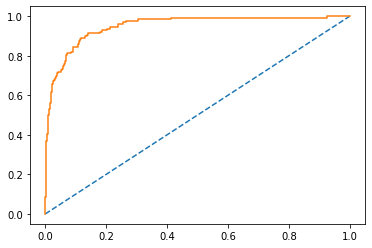

In [108]:
as_cm_cr(lda_model, X_test, y_test, y_pred_test, 'LDA', 'Test')
lda_auc_test,lda_fpr_test,lda_tpr_test = auc_roc(y_prob_pred_test, y_test)
lda_recall_test, lda_prec_test, lda_acc_test = model_eval_params(y_test, y_pred_test)

In [109]:
lda_test_metrics = [lda_acc_test, lda_recall_test, lda_prec_test, lda_auc_test]
print(lda_recall_test,lda_prec_test,lda_acc_test,lda_auc_test)

0.55 0.8 0.94 0.95


As shown above, the LDA model performance metrics like recall, accuracy and AUC score are consistent between train dataset and test dataset. This clearly shows the model neither overfits nor underfits and hence, reasonably a stable model.

### Performance Metrics

The performance metrics for the random forest model is given below

In [110]:
lda_index = ['Accuracy', 'Recall', 'Precision', 'AUC']
lda_metrics = pd.DataFrame({'LDA Train': lda_train_metrics, 'LDA Test': lda_test_metrics}, index=lda_index)
lda_metrics

,LDA Train,LDA Test
Accuracy,0.94,0.94
Recall,0.55,0.55
Precision,0.83,0.80
AUC,0.96,0.95


## Compare the performances of all the three models (include ROC Curve)

As we are done with model building exercise for the Company dataset with three algorithms logistic regression, random forest and LDa, let's compare the performance metrics of these three models and ROC curves. 

### Performance Metrics Comparison

In [111]:
perf_metrics = pd.concat([lr_metrics, rf_metrics, lda_metrics], axis=1)
perf_metrics

,LR Train,LR Test,RF Train,RF Test,LDA Train,LDA Test
Accuracy,0.87,0.86,0.98,0.98,0.94,0.94
Recall,0.77,0.73,0.89,0.87,0.55,0.55
Precision,0.45,0.43,0.93,0.92,0.83,0.80
AUC,0.90,0.90,0.99,0.99,0.96,0.95


### ROC Curves - Train Data

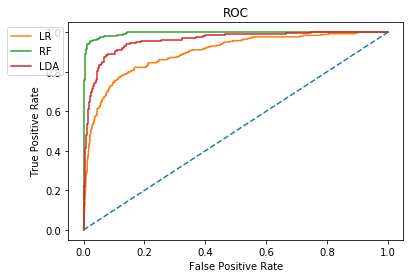

In [112]:
plt.plot([0, 1], [0, 1], linestyle='--')
plt.plot(lr_fpr_train, lr_tpr_train,label="LR")
plt.plot(rf_fpr_train,rf_tpr_train,label="RF")
plt.plot(lda_fpr_train,lda_tpr_train,label="LDA")


plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC')
plt.legend(bbox_to_anchor=(0., 1.), loc='best')

### ROC Curve - Test Data

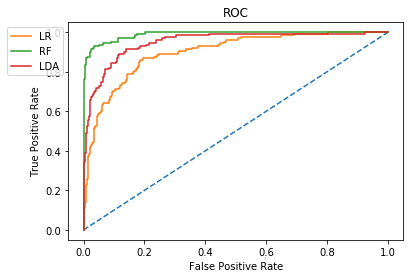

In [113]:
plt.plot([0, 1], [0, 1], linestyle='--')
plt.plot(lr_fpr_test, lr_tpr_test,label="LR")
plt.plot(rf_fpr_test,rf_tpr_test,label="RF")
plt.plot(lda_fpr_test,lda_tpr_test,label="LDA")


plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC')
plt.legend(bbox_to_anchor=(0., 1.), loc='best')

From the above performance metrics comparison and ROC curves for train and test datasets comparison,
1. The Company dataset is a smaller dataset in terms of number of rows, only 3586 rows.
2. In terms of number of variables, the Company dataset is reasonably on higher side with 65 columns.  As the number of variables more, it becomes so important to study the relationships and multicollinearity between these variables beore doing the data modelling.
3. In logistic regression exercise, several iterations have been done using stats models to find out and drop the variables that are insignificant.
4. The variance inflation factor has been determined for all the variables and those variables with variance inflation factor value of greater than 5 have been dropped as they would be an indication of multicollinearity.
5. The logistic regression model is consistent between train and test datasets in terms of accuracy and AUC score.  The accuracy and AUC score of logistic regression model is reasonably good.
6. The recall number of logistic regression model is reasonably good and consistent between train and test datasets.  The precision number of logistic regression model is poor and is only in the order of 40%+ and this is a good indication of type 1 error.
7. The LDA model has the performance metrics consistent between train and test datasets.  The LDA model has good accuracy, AUC score, and precision metrics, but, the model is poor in terms of recall.  The recall should be still better for the LDA model.  This is an indication of the type 2 error.
8. The random forest also has performance metrics consistent between train and test datasets.  Also, all the performance metrics are good for the random forest model like accuracy, AUC score, recall and precision.
9. From the ROC curves of train and test datasets shown above, the random forest model is good, followed by LDA and finally, the logistic regression model.

From the detailed model performance metrics comparison exercise that we have done above, the random forest model outperforms the LDA and logistic regression models for the Company dataset.


## Recommendation

Based on the model building exercise and predictions above,
1. In spite of the Company dataset has around 60+ variables, not all of them are significant in predicting the probability of default or a specific company defaulter or not.
2. Out of all the 60+ variables, only 8 variables are significant in prediction.  The most significant such variable is current_ratio_latest, the liquidity ratio, indicates the company's ability to pay short-term obligations within an year.  This has greater significance and inverse proportion to the prediction.  when the company's ability is less in paying the short-term obligations, the probability that the specific company would get defaulted is high.  This shows that companies should plan(as part of their annual budget) to separate keep adequate reserve in order to pay the short-term obligations faster irrespective of other factors.
3. The next variable which plays a significant role in prediction is interest cover ratio, how easily a company can pay interest on its outstanding debts.  Like current ratio latest, the interest cover ratio also has inverse proportion to the impact on prediction.  When a company is capable of easily paying interest on outstanding debts, the probably of that company becoming defaulter becomes less.  This would be a good indication for the companies that the timely periodic payment of interest on outstanding debts is critical as it reduces the probability of becoming a defaulter.
4. One of the significant variables that impacts the prediction positively is creditors velocity, average number of days taken by company to pay its suppliers.  This variable has reasonable significance and direct proportion to the prediction.  When the average number of days taken by a company to pay suppliers is more, the probability of that company becoming defaulter also would be more.  This mandates the companies to pay its suppliers at the earliest hence reducing the chance of becoming a defaulter.
5. The variables gross block percentage and net worth percentage also have some level of significance on the prediction though not very high.  Both of these variables have inverse proportion relation to the prediction.  When a company have high percentage of asset and net worth, the company has some chance to pay debts, suppliers either by selling some of its asserts etc. and this may prevent the company from becoming a defaulter.  Overall, when a company has high percentage of aasets and net worth, the probability of that company becoming a defaulter reduces.
6. When the market capitalization, the monetary value of company's shares is high, it reduces the probability of that company becoming a defaulter, in spite of the impact is not too high.
 